[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch48_LabCh48_Contrastive_Pretraining.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 48: Self-Supervised Learning** (Part X: Seeing More).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=48](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=48)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch48 - Contrastive pretraining in miniature
## Teach a small CNN to see digits without showing it one label, then find out what that was worth

This lab goes with **Chapter 48** of *The Why Book of Deep Learning, Part 2*.

Self-supervised learning invents a task whose answers are already in the data. Here the task is the one
SimCLR (2020) made famous: take a batch of images, make **two randomly distorted copies** of each, and ask the
network to work out which copy belongs with which. Nobody has to label anything for that. You will write the
loss by hand, look at the table of similarities it works on, pretrain an encoder on 60,000 unlabelled digits,
and then measure what the encoder learnt in the standard way: freeze it and train one `Dense` layer on top.

| The miniature | value |
|---|---|
| data | MNIST, 60,000 training images used **without their labels** |
| two views | crop and shift, small rotation, brightness, noise |
| encoder | three stride-2 convolutions and a global average: 28 × 28 × 1 → 128 numbers |
| projection head | `Dense(128, relu)` then `Dense(64)`; thrown away after pretraining |
| loss | InfoNCE, written by hand, temperature 0.2, batch of 256 pairs |
| pretraining | 2,000 steps (about 8.5 passes over the data) |
| test | a linear probe with 100, 1,000 and all 60,000 labels |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write vectorised augmentations and say what each one teaches the encoder to ignore | Steps 3 and 4 |
| Count the encoder and the projection head by hand | Step 5 |
| Write InfoNCE from a similarity matrix and predict its value before training | Steps 6 and 7 |
| Pretrain with two views and read the similarity matrix afterwards | Steps 8 and 9 |
| Judge a representation: linear probe, few labels, k nearest neighbours | Steps 10 to 13 |
| Compare fairly against supervised training from scratch, and say where it still wins | Step 11 |
| Show which augmentation the features depend on | Step 14 |
| Make a model collapse on purpose and recognise it | Step 15 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about four minutes on a laptop CPU. Most of it is Step 8 (the pretraining), Step 11 (three
> supervised runs) and Step 14 (six short pretraining runs). No GPU is needed. The only download is MNIST
> from `keras.datasets`.

> **Honest scale:** this is a miniature. The encoder has 92,672 parameters and trains for about a minute on
> small grey digits. SimCLR itself used a ResNet-50, colour photographs, batches of thousands and hundreds of
> passes over ImageNet. The numbers printed here compare the runs in this notebook with each other. They say
> nothing about what a full-size method scores. For a longer run, raise `PRETRAIN_STEPS` (Step 8) and
> `ABLATION_STEPS` (Step 14).

---
## Step 1 - Imports and one seed

In [1]:
import os, time, math
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 48
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=2, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The data: plenty of images, very few labels

MNIST has 60,000 training digits and 10,000 test digits, each 28 × 28 grey pixels. We use it in two ways.

* **For pretraining**: all 60,000 training images, with the labels put aside. The pretraining code never
  receives `y_train`.
* **For judging**: three labelled sets cut from the same training images: 100 labels (10 per digit), 1,000
  labels (100 per digit) and all 60,000. This is the situation the chapter describes: a large pile of raw
  data and a small pile that somebody paid to label.

The test set is the full 10,000 test images, and nothing ever trains on it.

**Predict:** 100 labels out of 60,000 is what fraction of the data?

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")[..., None]
x_test = (x_test / 255.0).astype("float32")[..., None]
print("x_train", x_train.shape, "| x_test", x_test.shape)

def label_subset(n, seed=1):
    """Indices of n training images, the same number from each class."""
    if n >= len(x_train):
        return np.arange(len(x_train))
    rng = np.random.default_rng(seed)
    per_class = n // 10
    return np.concatenate([rng.choice(np.where(y_train == c)[0], per_class, replace=False) for c in range(10)])

LABEL_SIZES = [100, 1000, 60000]
for n in LABEL_SIZES:
    idx = label_subset(n)
    print(f"{n:>6,} labels = {100 * n / len(x_train):6.2f}% of the training images, "
          f"per class: {np.bincount(y_train[idx], minlength=10).tolist()}")

x_train (60000, 28, 28, 1) | x_test (10000, 28, 28, 1)
   100 labels =   0.17% of the training images, per class: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
 1,000 labels =   1.67% of the training images, per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
60,000 labels = 100.00% of the training images, per class: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


---
## Step 3 - Two views: the augmentations

The supervision in this lab comes from one sentence: *two distorted copies of the same image are still the
same image.* So the distortions matter a great deal. Each one is a statement about what should **not** change
the answer:

| Augmentation | What it does here | What it tells the encoder to ignore |
|---|---|---|
| crop and shift | zooms into a random window covering 60% to 100% of each side | exact position and size |
| rotate | turns the image by up to about 20° either way | small tilt (handwriting slant) |
| brightness | multiplies the pixels by 0.6 to 1.4 and adds −0.2 to 0.2 | ink darkness and paper tone |
| noise | adds Gaussian noise with standard deviation 0.1 | grain in single pixels |

All four are written for a whole batch at once. Crop, shift and rotation are one affine transform per image,
done in a single TensorFlow call, so augmentation is not the slow part of training.

**Predict:** the rotation is limited to about 20°. What would go wrong for digits if it were allowed up to
180°? (Think of a 6.)

4,096 images augmented in 0.08 s; shape (4096, 28, 28, 1) | min 0.0 max 1.0


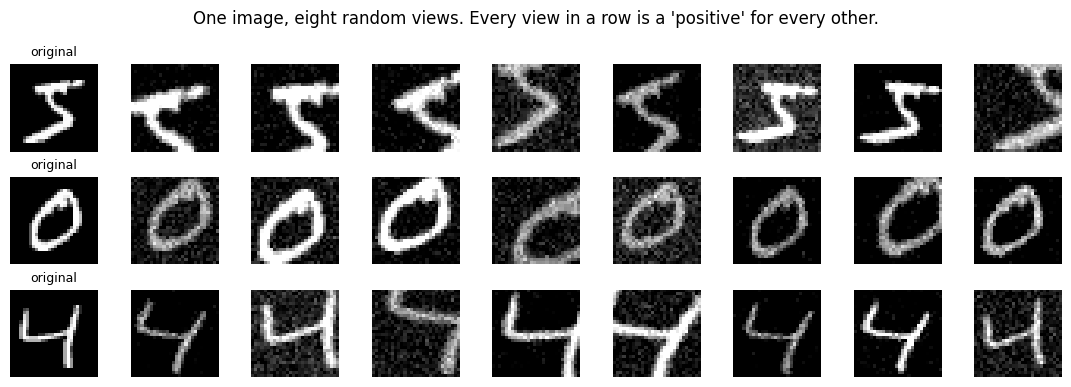

In [3]:
def augment(x, crop=True, rotate=True, bright=True, noise=True):
    """One random view of every image in the batch x, shape (n, 28, 28, 1), values 0 to 1."""
    n = tf.shape(x)[0]
    if crop or rotate:
        scale = tf.random.uniform([n], 0.6, 1.0) if crop else tf.ones([n])        # window side / image side
        angle = tf.random.uniform([n], -0.35, 0.35) if rotate else tf.zeros([n])   # radians; 0.35 is about 20 degrees
        room = (1.0 - scale) * 14.0                                                # how far the window can slide
        dx = tf.random.uniform([n], -1.0, 1.0) * room if crop else tf.zeros([n])
        dy = tf.random.uniform([n], -1.0, 1.0) * room if crop else tf.zeros([n])
        c, s = scale * tf.cos(angle), scale * tf.sin(angle)
        mid = 13.5                                                                 # centre of a 28-pixel side
        # each output pixel (u, v) reads the input at (a0*u + a1*v + a2, b0*u + b1*v + b2)
        a0, a1 = c, -s
        a2 = mid + dx - a0 * mid - a1 * mid
        b0, b1 = s, c
        b2 = mid + dy - b0 * mid - b1 * mid
        zero = tf.zeros([n])
        transforms = tf.stack([a0, a1, a2, b0, b1, b2, zero, zero], axis=1)
        x = tf.raw_ops.ImageProjectiveTransformV3(
            images=x, transforms=transforms, output_shape=[28, 28],
            interpolation="BILINEAR", fill_mode="CONSTANT", fill_value=0.0)
    if bright:
        x = x * tf.random.uniform([n, 1, 1, 1], 0.6, 1.4) + tf.random.uniform([n, 1, 1, 1], -0.2, 0.2)
    if noise:
        x = x + tf.random.normal(tf.shape(x), stddev=0.1)
    return tf.clip_by_value(x, 0.0, 1.0)

t = time.time()
views = augment(tf.constant(x_train[:4096]))
print("4,096 images augmented in", round(time.time() - t, 2), "s; shape", views.shape,
      "| min", float(tf.reduce_min(views)), "max", float(tf.reduce_max(views)))

fig, ax = plt.subplots(3, 9, figsize=(11, 3.9))
for r in range(3):
    ax[r, 0].imshow(x_train[r, :, :, 0], cmap="gray"); ax[r, 0].set_title("original", fontsize=9)
    many = augment(tf.repeat(tf.constant(x_train[r:r + 1]), 8, axis=0)).numpy()
    for k in range(8):
        ax[r, k + 1].imshow(many[k, :, :, 0], cmap="gray", vmin=0, vmax=1)
for a in ax.ravel(): a.axis("off")
plt.suptitle("One image, eight random views. Every view in a row is a 'positive' for every other."); plt.tight_layout(); plt.show()

### Why we see this

Every row is still plainly the same digit to you: bigger, tilted, paler, grainier, but the same. That is the
whole trick. You have just told the network, without a single label, eight things that should count as "the
same". The network's job will be to find features on which the copies in a row agree and the rows differ.

A rotation of 180° would turn a 6 into a 9, and then "two views of the same image" would no longer mean "the
same digit". **The augmentations are the human's knowledge of the problem.** Choose them badly and the encoder
learns to ignore the very thing you need.

---
## Step 4 - A batch of positive pairs

One training step takes a batch of N images and makes **view a** and **view b** of each. Image 5's view a and
image 5's view b are a **positive pair**. Image 5's view a and image 9's view b are a **negative pair**.

**Predict:** with N = 256 images in the batch, how many positive pairs are there, and how many negative
partners does each view a have among the views b?

view a (256, 28, 28, 1) | view b (256, 28, 28, 1)
positive pairs: 256 | negatives for each view a among the views b: 255 | cells in the N x N table: 65536


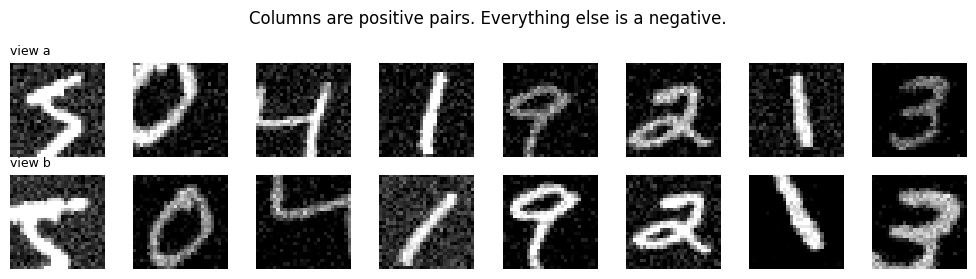

In [4]:
N = 256
batch = tf.constant(x_train[:N])
view_a, view_b = augment(batch), augment(batch)
print("view a", view_a.shape, "| view b", view_b.shape)
print("positive pairs:", N, "| negatives for each view a among the views b:", N - 1,
      "| cells in the N x N table:", N * N)

fig, ax = plt.subplots(2, 8, figsize=(10, 2.8))
for k in range(8):
    ax[0, k].imshow(view_a[k, :, :, 0], cmap="gray", vmin=0, vmax=1); ax[0, k].axis("off")
    ax[1, k].imshow(view_b[k, :, :, 0], cmap="gray", vmin=0, vmax=1); ax[1, k].axis("off")
ax[0, 0].set_title("view a", fontsize=9, loc="left"); ax[1, 0].set_title("view b", fontsize=9, loc="left")
plt.suptitle("Columns are positive pairs. Everything else is a negative."); plt.tight_layout(); plt.show()

---
## Step 5 - The encoder and the projection head

Two small networks.

* The **encoder** is the part we want to keep: three stride-2 convolutions (28 → 14 → 7 → 4) and a global
  average. An image goes in, a vector `h` of 128 numbers comes out.
* The **projection head** is a two-layer MLP that turns `h` into a vector `z` of 64 numbers. The loss is
  computed on `z`. After pretraining the head is thrown away (Step 12 shows why).

Count before Keras does. A convolution has `k·k·in·out + out` parameters (Chapter 14); a Dense layer has
`in·out + out` (Chapter 4).

**Predict:** the three convolutions have 320, 18,496 and 73,856 parameters. Which is largest, and why is the
first so small?

In [5]:
def make_encoder():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),    # 28 -> 14
        layers.Conv2D(64, 3, strides=2, padding="same", activation="relu"),    # 14 -> 7
        layers.Conv2D(128, 3, strides=2, padding="same", activation="relu"),   # 7 -> 4
        layers.GlobalAveragePooling2D(),                                       # (4, 4, 128) -> (128,)
    ], name="encoder")

def make_head():
    return keras.Sequential([
        layers.Input(shape=(128,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(64),
    ], name="projection_head")

encoder, head = make_encoder(), make_head()
conv1, conv2, conv3 = 3 * 3 * 1 * 32 + 32, 3 * 3 * 32 * 64 + 64, 3 * 3 * 64 * 128 + 128
head1, head2 = 128 * 128 + 128, 128 * 64 + 64
print("encoder by hand:", conv1, "+", conv2, "+", conv3, "=", conv1 + conv2 + conv3)
print("head by hand   :", head1, "+", head2, "=", head1 + head2)
assert encoder.count_params() == conv1 + conv2 + conv3 == 92672
assert head.count_params() == head1 + head2 == 24768
h = encoder(view_a[:8]); z = head(h)
print("images", view_a[:8].shape, "-> h", h.shape, "-> z", z.shape)
untrained_weights = encoder.get_weights()     # kept so that the 'untrained' encoder can be rebuilt later

encoder by hand: 320 + 18496 + 73856 = 92672
head by hand   : 16512 + 8256 = 24768
images (8, 28, 28, 1) -> h (8, 128) -> z (8, 64)


---
## Step 6 - InfoNCE by hand: a table of similarities and a quiz

Chapter 6 gave this loss two lines. Here are the working parts.

1. Scale every `z` to length 1. The dot product of two such vectors is their **cosine similarity**, between
   −1 and 1 (Chapter 18).
2. Compute the similarity of every view a with every view b: an **N × N table**. Row i is image i's view a,
   column j is image j's view b. The positives sit on the **diagonal**.
3. Read each row as a multiple-choice question: *"here are N candidates; which one is my partner?"* Divide
   the row by a small number, the **temperature**, and treat it as the logits of an N-way classifier whose
   correct answer is the diagonal. That is ordinary softmax cross-entropy (Chapter 6).
4. Ask the same question down each column, and average the two.

Below is a hand-made case with three pairs in two dimensions, small enough to check with a calculator, and
then the TensorFlow function the rest of the lab uses. Chapter 49 uses the same function for CLIP, with
images as view a and captions as view b.

**Predict:** if the encoder knows nothing, every candidate looks equally likely. What is the cross-entropy of
a blind guess among 3 candidates? Among 256?

In [6]:
def info_nce(za, zb, temperature):
    """InfoNCE for N positive pairs. za[i] and zb[i] are two views of item i.
    Returns (loss, sim): the scalar loss and the N x N table of cosine similarities."""
    za = tf.math.l2_normalize(za, axis=1)
    zb = tf.math.l2_normalize(zb, axis=1)
    sim = tf.matmul(za, zb, transpose_b=True)            # (N, N): row = a view a, column = a view b
    logits = sim / temperature
    labels = tf.range(tf.shape(sim)[0])                  # the partner of row i is column i
    xent = keras.losses.sparse_categorical_crossentropy
    loss_rows = tf.reduce_mean(xent(labels, logits, from_logits=True))                  # a looks for its b
    loss_cols = tf.reduce_mean(xent(labels, tf.transpose(logits), from_logits=True))    # b looks for its a
    return 0.5 * (loss_rows + loss_cols), sim

# three pairs, by hand in NumPy
toy_a = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0]], dtype="float32")
toy_b = np.array([[0.8, 0.6], [0.0, 2.0], [-0.6, -0.8]], dtype="float32")
na = toy_a / np.linalg.norm(toy_a, axis=1, keepdims=True)
nb = toy_b / np.linalg.norm(toy_b, axis=1, keepdims=True)
sim_np = na @ nb.T
print("similarity table (rows: a, columns: b)\n", sim_np)
T = 0.5
def row_loss(table):
    logits = table / T
    p = np.exp(logits) / np.exp(logits).sum(axis=1, keepdims=True)
    return -np.log(np.diag(p)).mean(), p
lr, p_rows = row_loss(sim_np); lc, _ = row_loss(sim_np.T)
print("softmax of each row at temperature 0.5\n", p_rows)
print("probability given to the true partner, row by row:", np.diag(p_rows))
print("loss by hand:", round(0.5 * (lr + lc), 4))
loss_tf, sim_tf = info_nce(toy_a, toy_b, T)
print("loss from info_nce:", round(float(loss_tf), 4))
assert abs(float(loss_tf) - 0.5 * (lr + lc)) < 1e-5 and np.allclose(sim_tf.numpy(), sim_np, atol=1e-6)
print("blind guess among 3:", round(math.log(3), 4), "| among 256:", round(math.log(256), 4))

similarity table (rows: a, columns: b)
 [[ 0.8  0.  -0.6]
 [ 0.6  1.  -0.8]
 [-0.8  0.   0.6]]
softmax of each row at temperature 0.5
 [[0.79 0.16 0.05]
 [0.3  0.68 0.02]
 [0.04 0.22 0.73]]
probability given to the true partner, row by row: [0.79 0.68 0.73]
loss by hand: 0.3083
loss from info_nce: 0.3083
blind guess among 3: 1.0986 | among 256: 5.5452


### Why we see this

The middle pair is perfectly aligned (similarity 1.00), so its row gives most of the probability to the right
column. The first and third pairs are only 0.80 similar and each has a distractor, so they are less sure. The
loss is the average surprise at the right answer, exactly as in any classifier.

A blind guess among N costs `ln N`. That number is the lab's reference line: **5.545 for a batch of 256**. A
loss near it means the network cannot tell partners from strangers.

One detail for readers of the SimCLR paper: its loss (called NT-Xent) also counts the other images *within
the same view* as negatives, giving each view 2N − 2 negatives instead of N − 1. The idea and the behaviour
are the same. The N × N form used here is the one CLIP uses.

---
## Step 7 - The similarity matrix before any training

Push the batch from Step 4 through the untrained encoder and head, and look at the table.

**Predict:** will the diagonal stand out? Will the loss be near 5.545?

In [7]:
TEMPERATURE = 0.2
loss0, sim0 = info_nce(head(encoder(view_a)), head(encoder(view_b)), TEMPERATURE)
sim0 = sim0.numpy()
off = ~np.eye(N, dtype=bool)
print("loss before training:", round(float(loss0), 3), "| blind guess:", round(math.log(N), 3))
print("mean similarity on the diagonal (positives):", round(float(np.diag(sim0).mean()), 3))
print("mean similarity off the diagonal (negatives):", round(float(sim0[off].mean()), 3))
print("top-left 6 x 6 corner of the table\n", sim0[:6, :6])

loss before training: 5.531 | blind guess: 5.545
mean similarity on the diagonal (positives): 0.945
mean similarity off the diagonal (negatives): 0.941
top-left 6 x 6 corner of the table
 [[0.97 0.96 0.91 0.99 0.95 0.97]
 [0.96 0.94 0.93 0.97 0.96 0.96]
 [0.94 0.93 0.9  0.97 0.92 0.95]
 [0.97 0.97 0.95 0.97 0.96 0.97]
 [0.95 0.94 0.91 0.98 0.95 0.95]
 [0.95 0.94 0.93 0.95 0.93 0.98]]


### Why we see this

An untrained network maps every digit to nearly the same direction: all the similarities are close to 1,
positives and negatives alike. The diagonal is a little higher, because two views of one image do share
pixels, and a random convolution passes some of that through. So the loss starts a little below a blind
guess. There is a faint signal for training to amplify.

---
## Step 8 - Pretrain: 2,000 steps without one label

The loop is short. Draw 256 images, make two views of each, encode, project, compute `info_nce`, take a
gradient step on the encoder and the head together. The learning rate follows a cosine from 0.002 to zero
(Chapter 8). Notice what the function receives: images only.

**Predict:** the loss starts near 5.5. Can it reach zero? (Two views of one image can be quite different,
and some other image in the batch is the same digit in similar handwriting.)

In [8]:
def pretrain(steps, batch_size=256, temperature=TEMPERATURE, loss_fn=info_nce, log_every=0, **aug):
    """Contrastive pretraining on x_train WITHOUT labels. Returns (encoder, head, list of losses)."""
    enc, hd = make_encoder(), make_head()
    opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(2e-3, steps))
    images = tf.constant(x_train)

    @tf.function(autograph=False)
    def step(idx):
        x = tf.gather(images, idx)
        va, vb = augment(x, **aug), augment(x, **aug)
        with tf.GradientTape() as tape:
            za = hd(enc(va, training=True), training=True)
            zb = hd(enc(vb, training=True), training=True)
            loss, _ = loss_fn(za, zb, temperature)
        weights = enc.trainable_variables + hd.trainable_variables
        opt.apply_gradients(zip(tape.gradient(loss, weights), weights))
        return loss

    rng = np.random.default_rng(SEED)
    losses, t0 = [], time.time()
    for i in range(steps):
        idx = rng.choice(len(x_train), batch_size, replace=False)
        losses.append(float(step(tf.constant(idx))))
        if log_every and (i % log_every == 0 or i == steps - 1):
            print(f"step {i:>5}  loss {np.mean(losses[-50:]):.3f}  ({time.time() - t0:.0f}s)")
    return enc, hd, losses

PRETRAIN_STEPS = 2000
t = time.time()
pre_encoder, pre_head, pre_losses = pretrain(PRETRAIN_STEPS, log_every=250)
print(f"pretraining took {time.time() - t:.0f}s: {PRETRAIN_STEPS} steps x 256 images = "
      f"{PRETRAIN_STEPS * 256:,} images seen = {PRETRAIN_STEPS * 256 / len(x_train):.1f} passes over the data")
print("mean loss, first 20 steps:", round(float(np.mean(pre_losses[:20])), 3),
      "| last 100 steps:", round(float(np.mean(pre_losses[-100:])), 3), "| blind guess:", round(math.log(256), 3))

step     0  loss 5.529  (1s)


step   250  loss 3.042  (7s)


step   500  loss 2.766  (13s)


step   750  loss 2.607  (18s)


step  1000  loss 2.530  (24s)


step  1250  loss 2.474  (30s)


step  1500  loss 2.420  (35s)


step  1750  loss 2.402  (41s)


step  1999  loss 2.396  (47s)
pretraining took 47s: 2000 steps x 256 images = 512,000 images seen = 8.5 passes over the data
mean loss, first 20 steps: 5.424 | last 100 steps: 2.397 | blind guess: 5.545


---
## Step 9 - The loss curve and the similarity matrix afterwards

Run the same batch as in Step 7 through the pretrained encoder and head.

**Predict:** what will the table look like now? What will the mean similarity of the negatives be: still
near 1, near 0, or negative?

loss on this batch after pretraining: 2.486
mean similarity on the diagonal (positives): 0.855
mean similarity off the diagonal (negatives): 0.006
rows whose largest entry is on the diagonal: 62.9% (blind guess: 0.39%)
top-left 6 x 6 corner of the table
 [[ 0.7  -0.01 -0.31 -0.2  -0.04 -0.2 ]
 [-0.17  0.58  0.45  0.07 -0.03  0.25]
 [-0.38 -0.19  0.79 -0.01  0.12 -0.24]
 [ 0.09  0.08 -0.    0.72 -0.05 -0.13]
 [ 0.15 -0.01 -0.23 -0.18  0.94 -0.12]
 [-0.18  0.18 -0.12 -0.21 -0.14  0.95]]


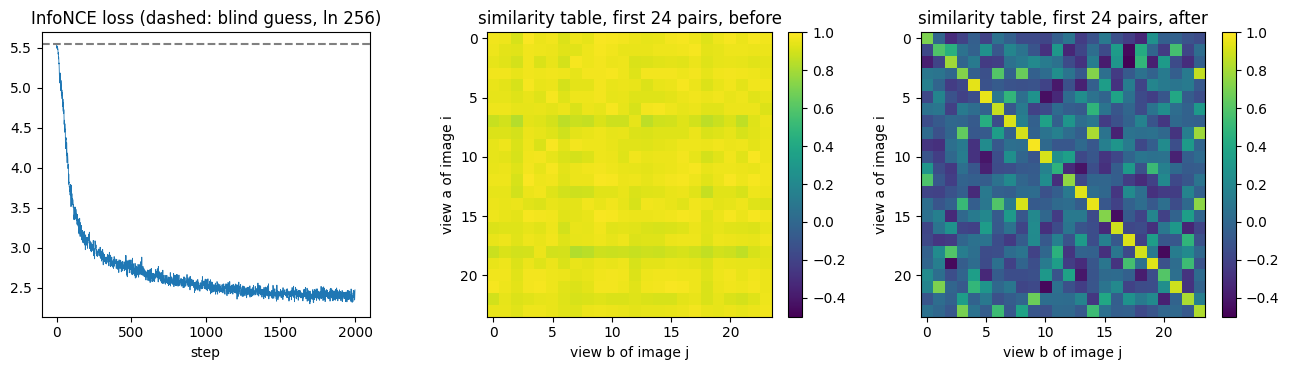

In [9]:
loss1, sim1 = info_nce(pre_head(pre_encoder(view_a)), pre_head(pre_encoder(view_b)), TEMPERATURE)
sim1 = sim1.numpy()
print("loss on this batch after pretraining:", round(float(loss1), 3))
print("mean similarity on the diagonal (positives):", round(float(np.diag(sim1).mean()), 3))
print("mean similarity off the diagonal (negatives):", round(float(sim1[off].mean()), 3))
right = float((sim1.argmax(axis=1) == np.arange(N)).mean())
print(f"rows whose largest entry is on the diagonal: {100 * right:.1f}% (blind guess: {100 / N:.2f}%)")
print("top-left 6 x 6 corner of the table\n", sim1[:6, :6])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(pre_losses, lw=0.6, color="tab:blue"); ax[0].axhline(math.log(256), color="gray", ls="--")
ax[0].set_title("InfoNCE loss (dashed: blind guess, ln 256)"); ax[0].set_xlabel("step")
for a, s, name in [(ax[1], sim0, "before"), (ax[2], sim1, "after")]:
    im = a.imshow(s[:24, :24], cmap="viridis", vmin=-0.5, vmax=1.0); a.set_title(f"similarity table, first 24 pairs, {name}")
    a.set_xlabel("view b of image j"); a.set_ylabel("view a of image i"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

### Why we see this

Before training the table is one flat colour. After training the diagonal is bright and the rest is spread
around zero: the network has used the whole sphere, placing different images in different directions. For
most rows the partner is now the largest entry.

The loss does not reach zero, and it should not. Look at the bright cells **off** the diagonal: those are
pairs of different images that the network finds similar. Check their labels in the exercises: most are the
same digit. The loss calls them negatives and pushes them apart, although they are exactly what we hope the
encoder will group. These are **false negatives**, a built-in flaw of the method when no labels are used.

---
## Step 10 - The linear probe: what did the encoder learn?

A low contrastive loss is not the goal. The goal is features that make *later* tasks easy. The standard test
is the **linear probe**: freeze the encoder, and train one `Dense(10)` layer on its 128 outputs. A linear
layer can only draw flat boundaries, so it scores well only if the encoder has already pulled the classes
apart.

Because the encoder is frozen, its output for each image never changes. So we compute all the features once
and train the Dense layer on the stored features: the same result as a frozen encoder with a Dense layer on
top, at a fraction of the time. The probe has 128·10 + 10 = 1,290 parameters.

We probe two encoders with 100, 1,000 and 60,000 labels: the **untrained** one from Step 5 (random weights)
and the **pretrained** one.

**Predict:** how well can a linear layer do on the features of a network that was never trained? And where
will pretraining help most: with 100 labels or with 60,000?

In [10]:
def features(enc, x):
    return enc.predict(x, batch_size=1000, verbose=0)

def linear_probe(f_train, f_test, sizes=LABEL_SIZES):
    """Train one Dense(10) layer on frozen features, once for each label budget. Returns test accuracies."""
    mean, std = f_train.mean(axis=0), f_train.std(axis=0) + 1e-6      # scale the features; uses no labels
    f_train, f_test = (f_train - mean) / std, (f_test - mean) / std
    accs = []
    for n in sizes:
        idx = label_subset(n)
        f, y = tf.constant(f_train[idx]), tf.constant(y_train[idx].astype("int32"))
        probe = layers.Dense(10, kernel_initializer="zeros")          # the whole trainable model
        probe.build((None, f_train.shape[1]))
        steps, batch_size = (300, n) if n <= 1000 else (1500, 512)    # small sets: the full set every step
        opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(1e-2, steps))

        @tf.function(autograph=False)
        def step(i):
            with tf.GradientTape() as tape:
                loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(
                    tf.gather(y, i), probe(tf.gather(f, i)), from_logits=True))
            opt.apply_gradients(zip(tape.gradient(loss, probe.trainable_variables), probe.trainable_variables))

        rng = np.random.default_rng(0)
        for _ in range(steps):
            step(tf.constant(rng.choice(n, batch_size, replace=False)))
        accs.append(float((probe(f_test).numpy().argmax(axis=1) == y_test).mean()))
    return accs

untrained_encoder = make_encoder(); untrained_encoder.set_weights(untrained_weights)
f_un_train, f_un_test = features(untrained_encoder, x_train), features(untrained_encoder, x_test)
f_pre_train, f_pre_test = features(pre_encoder, x_train), features(pre_encoder, x_test)
print("features:", f_pre_train.shape, f_pre_test.shape, "| probe parameters:", 128 * 10 + 10)
acc_untrained = linear_probe(f_un_train, f_un_test)
acc_pretrained = linear_probe(f_pre_train, f_pre_test)
print("labels            ", "".join(f"{n:>10,}" for n in LABEL_SIZES))
print("untrained + probe ", "".join(f"{100 * a:>9.2f}%" for a in acc_untrained))
print("pretrained + probe", "".join(f"{100 * a:>9.2f}%" for a in acc_pretrained))

features: (60000, 128) (10000, 128) | probe parameters: 1290


labels                    100     1,000    60,000
untrained + probe      52.52%    73.92%    84.91%
pretrained + probe     85.26%    94.58%    97.69%


---
## Step 11 - Against supervised training from scratch

The honest opponent is not the untrained encoder. It is what you would do without self-supervision: take the
**same encoder architecture**, put `Dense(10)` on top, and train all of it on the labels you have.

Each run gets enough steps to fit its own data (300 steps for 100 labels, 1,000 for 1,000 and 3,000 for all
60,000, which is 6.4 passes) and a learning rate tuned a little, so that the opponent is not a straw man.

**Predict:** with 100 labels, which wins: 92,672 parameters trained on 100 images, or 1,290 parameters trained
on frozen self-supervised features? And with all 60,000 labels?

three supervised runs took 27s; each trains 93,962 parameters

test accuracy                     100     1,000    60,000   labels
untrained encoder + probe      52.52%    73.92%    84.91%
pretrained encoder + probe     85.26%    94.58%    97.69%
supervised from scratch        63.02%    90.67%    98.32%


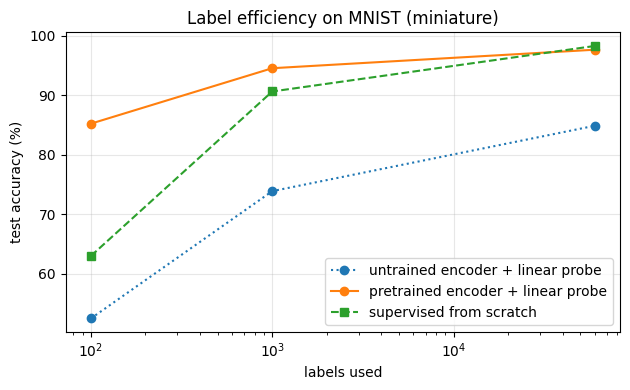

In [11]:
def supervised_from_scratch(n):
    idx = label_subset(n)
    x, y = tf.constant(x_train[idx]), tf.constant(y_train[idx].astype("int32"))
    model = keras.Sequential([make_encoder(), layers.Dense(10)])
    steps, batch_size = {100: (300, 32), 1000: (1000, 64)}.get(n, (3000, 128))
    opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(3e-3, steps))

    @tf.function(autograph=False)
    def step(i):
        with tf.GradientTape() as tape:
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(
                tf.gather(y, i), model(tf.gather(x, i), training=True), from_logits=True))
        opt.apply_gradients(zip(tape.gradient(loss, model.trainable_variables), model.trainable_variables))

    rng = np.random.default_rng(0)
    for _ in range(steps):
        step(tf.constant(rng.choice(n, batch_size, replace=False)))
    acc = float((model.predict(x_test, batch_size=1000, verbose=0).argmax(axis=1) == y_test).mean())
    return acc, model.count_params()

t = time.time()
acc_supervised = []
for n in LABEL_SIZES:
    a, n_params = supervised_from_scratch(n)
    acc_supervised.append(a)
print(f"three supervised runs took {time.time() - t:.0f}s; each trains {n_params:,} parameters")
assert n_params == 92672 + 1290
print()
print("test accuracy             ", "".join(f"{n:>10,}" for n in LABEL_SIZES), "  labels")
print("untrained encoder + probe ", "".join(f"{100 * a:>9.2f}%" for a in acc_untrained))
print("pretrained encoder + probe", "".join(f"{100 * a:>9.2f}%" for a in acc_pretrained))
print("supervised from scratch   ", "".join(f"{100 * a:>9.2f}%" for a in acc_supervised))

plt.figure(figsize=(6.4, 4))
for accs, name, style in [(acc_untrained, "untrained encoder + linear probe", "o:"),
                          (acc_pretrained, "pretrained encoder + linear probe", "o-"),
                          (acc_supervised, "supervised from scratch", "s--")]:
    plt.plot(LABEL_SIZES, [100 * a for a in accs], style, label=name)
plt.xscale("log"); plt.xlabel("labels used"); plt.ylabel("test accuracy (%)"); plt.grid(alpha=0.3)
plt.title("Label efficiency on MNIST (miniature)"); plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

Read the table one column at a time.

* **100 labels.** The pretrained encoder with a linear probe is far ahead. The supervised network has to
  learn what a stroke is, what a loop is and which digit is which, all from ten examples of each digit. The
  probe only has to learn which digit is which; the 60,000 unlabelled images already taught the rest.
* **1,000 labels.** The gap narrows.
* **All labels.** Supervised training from scratch wins. With plenty of labels, features trained for exactly
  this task beat frozen features trained for a different one. That is the normal result, not a failure: the
  value of self-supervision is at the label-poor end, and it is realised fully only when the pretrained
  encoder is then **fine-tuned** (Chapter 39) instead of frozen. Exercise 3 asks you to do that.

Note the untrained row too. A random encoder with a linear probe is not at 10%. Random convolutions already
keep a great deal of information, which is why "better than chance" is never the right baseline for a
representation.

---
## Step 12 - Two more ways to judge, and the head you should throw away

**k nearest neighbours.** No training at all: for each test image, find the 5 most similar training images
(cosine similarity of the features) and take a vote of their labels. It asks directly whether neighbours in
feature space are the same class. We use 10,000 labelled training images as the memory.

**The projection head.** The loss was computed on `z`, the output of the head. So is `z` not the better
feature? Probe both with 1,000 labels.

**Predict:** which gives the better linear probe: `h` (128 numbers, before the head) or `z` (64 numbers, the
vectors the loss worked on)?

In [12]:
def knn_accuracy(f_train, y_tr, f_test, y_te, k=5):
    a = f_train / (np.linalg.norm(f_train, axis=1, keepdims=True) + 1e-9)
    b = f_test / (np.linalg.norm(f_test, axis=1, keepdims=True) + 1e-9)
    nearest = np.argpartition(-(b @ a.T), k, axis=1)[:, :k]
    votes = y_tr[nearest]
    pred = np.array([np.bincount(v, minlength=10).argmax() for v in votes])
    return float((pred == y_te).mean())

memory = label_subset(10000)
print("5-nearest-neighbour accuracy, 10,000 labelled images as memory")
print("  untrained encoder :", f"{100 * knn_accuracy(f_un_train[memory], y_train[memory], f_un_test, y_test):.2f}%")
print("  pretrained encoder:", f"{100 * knn_accuracy(f_pre_train[memory], y_train[memory], f_pre_test, y_test):.2f}%")

z_train = pre_head.predict(f_pre_train, batch_size=1000, verbose=0)
z_test = pre_head.predict(f_pre_test, batch_size=1000, verbose=0)
acc_h = linear_probe(f_pre_train, f_pre_test, sizes=[1000])[0]
acc_z = linear_probe(z_train, z_test, sizes=[1000])[0]
print("linear probe with 1,000 labels")
print(f"  on h, before the head ({f_pre_train.shape[1]} numbers): {100 * acc_h:.2f}%")
print(f"  on z, after the head  ({z_train.shape[1]} numbers): {100 * acc_z:.2f}%")

5-nearest-neighbour accuracy, 10,000 labelled images as memory


  untrained encoder : 82.53%


  pretrained encoder: 95.48%


linear probe with 1,000 labels
  on h, before the head (128 numbers): 94.58%
  on z, after the head  (64 numbers): 93.88%


### Why we see this

The loss rewards `z` for being **identical** across the two views. To achieve that, the last layers must
discard whatever the augmentations change: size, tilt, brightness. Some of that information is useful later.
The head is where the discarding happens, so the layer before it, `h`, keeps more. On these simple digits the
difference is small, because little of what the augmentations change is needed to name a digit. SimCLR
(2020) reported a far larger gap on ImageNet photographs, and that is why the head is used for training and
then removed. Evaluating with the head still attached is a classic way to under-report your own method.

---
## Step 13 - Look at the space: before and after

Take 2,000 test images, compute their 128 features, and squash them to 2-D with PCA (the two directions of
largest variance, found with an SVD; Chapter 27 met PCA as the linear autoencoder). The colours are the true
digits, used for colouring only.

A number to go with the picture: the mean cosine similarity between two images of the **same** digit and of
**different** digits, measured on the centred features.

**Predict:** the encoder never saw a label. Will images of the same digit sit together anyway?

untrained encoder                      same digit +0.277 | different digits -0.028 | gap 0.305
pretrained encoder (no labels used)    same digit +0.380 | different digits -0.041 | gap 0.421


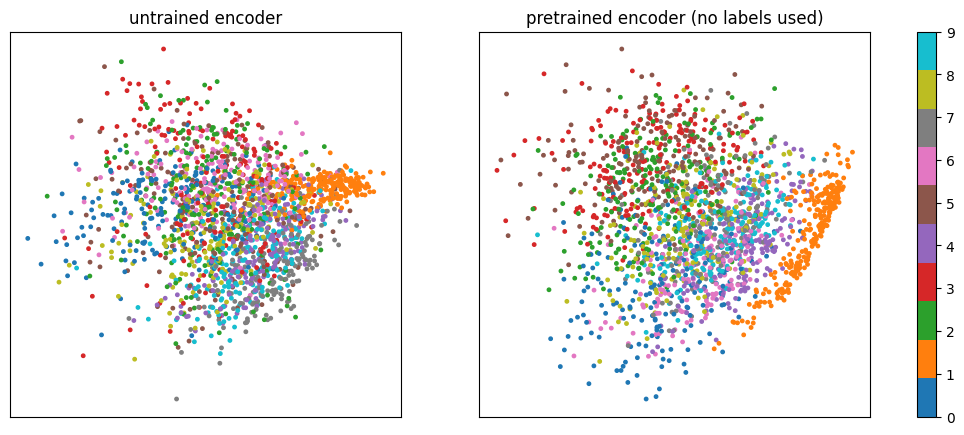

In [13]:
def pca_2d(f):
    f = f - f.mean(axis=0)
    _, _, vt = np.linalg.svd(f, full_matrices=False)
    return f @ vt[:2].T

def same_vs_different(f, y):
    f = f - f.mean(axis=0)
    f = f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-9)
    s = f @ f.T
    same = (y[:, None] == y[None, :]) & ~np.eye(len(y), dtype=bool)
    diff = y[:, None] != y[None, :]
    return float(s[same].mean()), float(s[diff].mean())

sub = np.random.default_rng(3).choice(len(x_test), 2000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, f, name in [(ax[0], f_un_test[sub], "untrained encoder"), (ax[1], f_pre_test[sub], "pretrained encoder (no labels used)")]:
    p = pca_2d(f)
    sc = a.scatter(p[:, 0], p[:, 1], c=y_test[sub], cmap="tab10", s=6)
    a.set_title(name); a.set_xticks([]); a.set_yticks([])
    same, diff = same_vs_different(f, y_test[sub])
    print(f"{name:<38} same digit {same:+.3f} | different digits {diff:+.3f} | gap {same - diff:.3f}")
plt.colorbar(sc, ax=ax, ticks=range(10), fraction=0.025); plt.show()

### Why we see this

Nobody told the encoder that there are ten digits. It was told only that a zoomed, tilted, paler copy of an
image is the same image. To satisfy that for 60,000 images it had to build features of shape: loops, strokes,
crossings. Images that share those features are mostly the same digit, so the classes separate as a side
effect. **The network does not care about the task; you care about the features it had to build to solve it.**

A 2-D picture of a 128-dimensional space hides most of the structure, so trust the probe numbers over the
picture.

---
## Step 14 - Remove one augmentation at a time

If the augmentations are the supervision, removing one should change what the encoder learns. Six short
pretraining runs of 400 steps each: all four augmentations, each one removed in turn, and none at all. Each is
judged by a linear probe with 1,000 labels.

With no augmentation the two views are **identical**, so finding the partner is trivial.

**Predict:** which removal hurts most? And what will the contrastive loss be when there is no augmentation:
high or low? Will that run have the best features?

In [14]:
ABLATION_STEPS = 400
runs = [("all four", {}), ("no crop and shift", {"crop": False}), ("no rotation", {"rotate": False}),
        ("no brightness", {"bright": False}), ("no noise", {"noise": False}),
        ("no augmentation", {"crop": False, "rotate": False, "bright": False, "noise": False})]
t = time.time()
ablation = []
for name, aug in runs:
    enc, _, losses = pretrain(ABLATION_STEPS, **aug)
    acc = linear_probe(features(enc, x_train), features(enc, x_test), sizes=[1000])[0]
    ablation.append((name, float(np.mean(losses[-50:])), acc))
print(f"six runs of {ABLATION_STEPS} steps took {time.time() - t:.0f}s")
print(f"{'augmentations':<20}{'final loss':>12}{'probe, 1,000 labels':>22}")
for name, loss, acc in ablation:
    print(f"{name:<20}{loss:>12.3f}{100 * acc:>21.2f}%")
print(f"{'(untrained encoder)':<20}{'':>12}{100 * acc_untrained[1]:>21.2f}%")

six runs of 400 steps took 69s
augmentations         final loss   probe, 1,000 labels
all four                   2.929                92.95%
no crop and shift          2.082                90.11%
no rotation                2.429                91.67%
no brightness              2.721                92.59%
no noise                   2.898                93.17%
no augmentation            1.231                79.75%
(untrained encoder)                             73.92%


### Why we see this

Two lessons.

**The loss and the features disagree.** The run with no augmentation has by far the lowest loss, because
matching an image to an identical copy of itself needs no understanding: any detail of the pixels will do.
Its features are among the worst. A contrastive loss is only comparable between runs that have the same
augmentations, batch size and temperature. Never choose augmentations by the pretraining loss.

**Crop and shift carries the most weight here.** Without it, the two views line up pixel for pixel apart from
a small tilt, and the task can be solved by position-bound detail. With it, the network has to recognise the
same shape at a different place and size. SimCLR (2020) reported the same pattern on photographs: random
cropping, combined with colour distortion, mattered most.

These are single short runs with one seed. Differences of a point or so between rows are noise; read the
large gaps only.

---
## Step 15 - Collapse on purpose: take the negatives away

What are the negatives for? Remove them and see. The loss below keeps only the "pull the partners together"
half: one minus the mean cosine similarity of each positive pair. It has an easy perfect solution.

To see what happens we measure the **spread** of the `z` vectors: the standard deviation of each coordinate
over 2,000 images, averaged, and scaled so that vectors spread evenly over the sphere score 1 and identical
vectors score 0.

**Predict:** what will this loss go to, and what will the network do to get there?

In [15]:
def positives_only(za, zb, temperature):
    za = tf.math.l2_normalize(za, axis=1)
    zb = tf.math.l2_normalize(zb, axis=1)
    sim = tf.matmul(za, zb, transpose_b=True)
    return 1.0 - tf.reduce_mean(tf.linalg.diag_part(sim)), sim

def spread(enc, hd, x):
    z = hd(enc(x)).numpy()
    z = z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-9)
    return float(z.std(axis=0).mean() * np.sqrt(z.shape[1]))

col_encoder, col_head, col_losses = pretrain(300, loss_fn=positives_only)
probe_x = x_test[:2000]
print("positives-only loss, first step:", round(col_losses[0], 4), "| last step:", round(col_losses[-1], 6))
print("spread of z (1 = evenly over the sphere, 0 = every image at one point)")
print("  untrained          :", round(spread(untrained_encoder, head, probe_x), 3))
print("  InfoNCE, 2,000 steps:", round(spread(pre_encoder, pre_head, probe_x), 3))
print("  positives only     :", round(spread(col_encoder, col_head, probe_x), 3))
acc_collapsed = linear_probe(features(col_encoder, x_train), features(col_encoder, x_test), sizes=[1000])[0]
print("linear probe with 1,000 labels on the encoder")
print(f"  untrained {100 * acc_untrained[1]:.2f}% | InfoNCE {100 * acc_pretrained[1]:.2f}% | positives only {100 * acc_collapsed:.2f}%")
print(f"\nwhole notebook: {time.time() - t_start:.0f}s")

positives-only loss, first step: 0.0311 | last step: 2e-06
spread of z (1 = evenly over the sphere, 0 = every image at one point)
  untrained          : 0.342
  InfoNCE, 2,000 steps: 0.983
  positives only     : 0.002


linear probe with 1,000 labels on the encoder
  untrained 73.92% | InfoNCE 94.58% | positives only 58.56%

whole notebook: 162s


### Why we see this

The loss falls to almost exactly zero, the best value it can have, and the model is useless. The network
found the trivial answer: send **every** image to the same point. Then every pair of views agrees perfectly,
and so does every pair of strangers. This is **collapse**. The spread of `z` near zero is how you detect it;
the loss will never tell you, because for the loss this is success.

The negatives in InfoNCE are what forbid it: the loss is low only if partners are close **and** strangers are
far apart. BYOL (2020) and DINO (2021) drop the negatives and avoid collapse by other means (a slowly moving
teacher, a stop-gradient, centring); the chapter describes them, and why they work is still being studied.

The probe on the collapsed encoder is printed so that you can see how far the damage reaches back from `z`
into `h`. Compare it with the untrained encoder: pretraining with a broken objective can leave you **worse
off than not training at all**.

---
## Trials: change one thing at a time

Each trial changes one number or one line. Write your prediction first.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | `TEMPERATURE = 0.05`, then `1.0` (rerun Steps 8 and 10) | Does a sharper softmax (small temperature) help or hurt the probe? What happens to the loss value? | |
| 2 | `pretrain(..., batch_size=32)` with the steps raised to 16,000 so the images seen stay equal | Fewer negatives per question. Easier or harder task? Better or worse features? | |
| 3 | `PRETRAIN_STEPS = 500`, then `4000` | How much of the 100-label gain arrives in the first quarter of training? | |
| 4 | Rotation range `0.35` → `3.14` in `augment` | Which digits will the probe now confuse? | |
| 5 | Crop range `0.6` → `0.3` (much stronger zoom) | Is a harder task always a better teacher? | |
| 6 | Replace the head by `layers.Dense(64)` alone, or remove it and compute the loss on `h` | What happens to the probe on `h`? | |
| 7 | Swap `keras.datasets.mnist` for `keras.datasets.fashion_mnist` | Will the gain over the untrained encoder be larger or smaller? (Do small crops of a shoe and a shirt differ as clearly as crops of a 3 and a 7?) | |
| 8 | In Step 15, keep the positives-only loss but stop the gradient through `zb` (`tf.stop_gradient`) | Is a stop-gradient alone enough to prevent collapse here? | |

## Exercises

1. **Find the false negatives.** In the table `sim1` from Step 9, find the 20 largest entries off the
   diagonal and print the labels `y_train[i]`, `y_train[j]` of each pair. What fraction are the same digit?
   What does the loss do to those pairs?
2. **Supervised contrastive, in three lines.** Using the labels of the batch, build a mask of same-class
   pairs and treat them all as positives in the loss. Pretrain with 1,000 labelled images only and compare
   the probe.
3. **Fine-tune instead of probing.** Put `Dense(10)` on the pretrained encoder, leave everything trainable,
   use a learning rate of 3e-4, and train on 100 and on 1,000 labels. Compare with the probe and with
   supervised from scratch. Chapter 39 explains what you see.
4. **NT-Xent.** Write SimCLR's exact loss: stack the two views into 2N vectors, build the 2N × 2N table,
   mask its diagonal, and give each row one positive. Check that with random inputs its value is near
   `ln(2N − 1)`.
5. **A pretext task from before 2018.** Rotate each image by 0°, 90°, 180° or 270° and train the encoder to
   predict which. Probe it. Why is this task badly suited to digits, and to which digits in particular?
6. **Uniformity and alignment.** Compute two numbers for the pretrained `z`: the mean squared distance
   between partners (alignment), and the log of the mean of `exp(−2·distance²)` over all pairs
   (uniformity). Track both over training.

## Cheat sheet

| Idea | One line |
|---|---|
| Self-supervised learning | invent a task whose answers are already in the data; keep the features, discard the task |
| Positive pair | two random views of the same image |
| Negative | any other image in the batch (sometimes wrongly: a false negative) |
| InfoNCE | cross-entropy on the N × N similarity table, the diagonal being the right answer; a blind guess costs ln N |
| Temperature | divides the similarities before the softmax; small = fuss about the hardest negatives |
| Projection head | trained with the encoder, thrown away afterwards; probe the layer before it |
| Linear probe | freeze the encoder, train one Dense layer; measures what is linearly readable |
| Collapse | every image mapped to one vector; perfect agreement, zero information; check the spread, not the loss |
| Augmentations | the human's prior: each one names something the features should ignore |
| Where it pays | few labels. With plenty of labels, supervised training from scratch catches up or wins |

```python
def info_nce(za, zb, temperature):
    za = tf.math.l2_normalize(za, axis=1); zb = tf.math.l2_normalize(zb, axis=1)
    sim = tf.matmul(za, zb, transpose_b=True)              # (N, N) cosine similarities
    labels = tf.range(tf.shape(sim)[0])                    # partner of row i is column i
    xent = keras.losses.sparse_categorical_crossentropy
    loss = 0.5 * (tf.reduce_mean(xent(labels, sim / temperature, from_logits=True))
                  + tf.reduce_mean(xent(labels, tf.transpose(sim) / temperature, from_logits=True)))
    return loss, sim
```